In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from pygam import LinearGAM, s
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from scipy import stats

In [16]:
grid = gpd.read_file(
    "C:/Floor/Documenten/ENV-year-2/Thesis/Data/Zorgvliet/master_grid_zorgvliet.gpkg",
    # layer="master_grid_with_features",
)
# Reproject to EPSG:28992 (RD New - meters) so calculations work properly
grid = grid.to_crs("EPSG:28992")

#remove a few columns
# grid.drop(
#     columns=['LST_2025-07-25 16:45', 'LST_2025-08-19 06:10'], inplace=True)

# show the columns of the grid
grid.columns

Index(['fid_2', 'name', 'description', 'id', 'oce_id', 'guid', 'wijkcode',
       'wijknaam', 'stadsdeelco', 'oppervlakte', 'omtrek', 'grid_id',
       'percentage_verharding', 'percentage_onverhard', 'percentage_water',
       'percentage_green_shadow', 'percentage_grey_shadow',
       'percentage_combined_shadow', 'boomkroonvolume_m3',
       'boomkroonoppervlakte_m2', 'biomassa_bermudez_kg',
       'LST_2025-06-02 13:54', 'LST_2025-06-02 15:30', 'LST_2025-06-03 13:05',
       'LST_2025-06-04 12:18', 'LST_2025-06-05 13:06', 'LST_2025-06-06 12:17',
       'LST_2025-06-09 11:29', 'LST_2025-06-11 11:29', 'LST_2025-06-12 09:04',
       'LST_2025-06-15 09:51', 'LST_2025-06-16 09:03', 'LST_2025-06-18 07:26',
       'LST_2025-06-29 04:58', 'LST_2025-06-30 04:10', 'LST_2025-07-10 22:26',
       'LST_2025-07-11 21:37', 'LST_2025-07-30 15:55', 'LST_2025-08-06 11:52',
       'LST_2025-08-09 12:39', 'LST_2025-08-10 11:50', 'LST_2025-08-11 09:25',
       'LST_2025-08-13 09:24', 'LST_2025-08-13 11

In [17]:
def determine_time_of_day(column_name):
    """
    Determine the time of day based on the hour in the given column.
    Returns a new column with the time of day categories.
    """
    # Check if it's an LST column
    if not column_name.startswith("LST_"):
        return None
    
    # Extract the time part after the space (e.g., '03:44')
    time_str = column_name.split(" ")[1]
    hour = int(time_str.split(":")[0])
    
    # Use the 6-hour blocks definition
    if 0 <= hour < 6:
        return "Night"
    elif 6 <= hour < 12:
        return "Morning"
    elif 12 <= hour < 18:
        return "Afternoon"
    else:
        return "Evening"

def compute_mlr(df, target_col, feature_cols):
  """ Computes Multiple Linear Regression (MLR) using statsmodels.

  Parameters:
  - df: pandas DataFrame or GeoDataFrame
  - target_col: string, name of the dependent variable (e.g., 'LST_Mean_Afternoon')
  - feature_cols: list of strings, independent predictor variables

  Returns:
  - fitted OLS model results object
  """
  # Construct the formula: target ~ feature1 + feature2 + ...
  formula = f"{target_col} ~ " + " + ".join(feature_cols)

  # Fit Ordinary Least Squares model
  model = smf.ols(formula, data=df).fit()
  return model

def compute_gam(df, target_col, feature_cols, n_splines=5):
  """Computes a Generalized Additive Model (GAM) using pygam.

  Parameters:
  - df: pandas DataFrame or GeoDataFrame
  - target_col: string, name of the dependent variable
  - feature_cols: list of strings, independent predictor variables
  - n_splines: int, number of splines for smoothing functions

  Returns:
  - fitted LinearGAM object and the cleaned subset DataFrame used for fitting
  """
  # Drop missing values for the selected columns
  data_subset = df[feature_cols + [target_col]].dropna()

  X = data_subset[feature_cols].values
  y = data_subset[target_col].values

  # Build the GAM formula by summing spline terms (s) for each feature index
  gam_formula = s(0, n_splines=n_splines)
  for i in range(1, len(feature_cols)):
    gam_formula += s(i, n_splines=n_splines)

  # Fit the model using LinearGAM and the combined formula
  gam = LinearGAM(gam_formula).fit(X, y)
  return gam, data_subset

In [18]:
lst_columns = [col for col in grid.columns if col.startswith("LST_")]

tod_dict = {"Night": [], "Morning": [], "Afternoon": [], "Evening": []}

for col in lst_columns:
    tod = determine_time_of_day(col)
    if tod:
        tod_dict[tod].append(col)

for tod, columns in tod_dict.items():
    if columns: 
        grid[f"LST_Mean_{tod}"] = grid[columns].mean(axis=1)
    else:
        grid[f"LST_Mean_{tod}"] = np.nan

print(grid[['LST_Mean_Morning',"LST_Mean_Afternoon", 'LST_Mean_Evening', "LST_Mean_Night"]].head())

   LST_Mean_Morning  LST_Mean_Afternoon  LST_Mean_Evening  LST_Mean_Night
0         26.202500           27.911251         18.654999       18.383333
1         25.649375           26.981249         18.510000       18.333334
2         26.760625           28.563751         18.629999       18.276667
3         26.128125           28.180000         18.500000       18.570000
4         25.964375           27.845001         18.500000       18.580000


                            OLS Regression Results                            
Dep. Variable:     LST_Mean_Afternoon   R-squared:                       0.586
Model:                            OLS   Adj. R-squared:                  0.585
Method:                 Least Squares   F-statistic:                     1099.
Date:                Wed, 11 Nov 2026   Prob (F-statistic):               0.00
Time:                        11:25:56   Log-Likelihood:                -4290.3
No. Observations:                2334   AIC:                             8589.
Df Residuals:                    2330   BIC:                             8612.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                 

C:\Users\hoeks\AppData\Local\Temp\ipykernel_5496\4219451090.py:15: UserWarning: KNOWN BUG: p-values computed in this summary are likely much smaller than they should be. 
 
Please do not make inferences based on these values! 

Collaborate on a solution, and stay up to date at: 
github.com/dswah/pyGAM/issues/163 

  print(gam_model.summary())


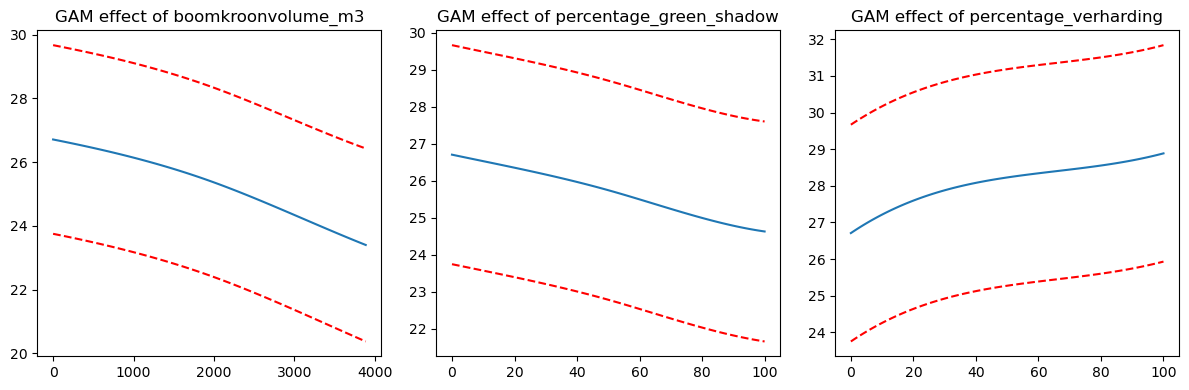

In [19]:
# Define your predictors and target variable
target = 'LST_Mean_Afternoon'
features = [
    'boomkroonvolume_m3',
    'percentage_green_shadow',
    'percentage_verharding',
]

# 1. Compute and summarize Multiple Linear Regression
mlr_model = compute_mlr(grid, target, features)
print(mlr_model.summary())

# 2. Compute Generalized Additive Model
gam_model, clean_data = compute_gam(grid, target, features)
print(gam_model.summary())

# Optional: Plot the partial dependence of each feature in the GAM
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
for i, feature in enumerate(features):
  plt.subplot(1, len(features), i + 1)
  XX = gam_model.generate_X_grid(term=i)
  plt.plot(XX[:, i], gam_model.predict(XX))
  plt.plot(XX[:, i], gam_model.prediction_intervals(XX, width=0.95), color='r', ls='--')
  plt.title(f'GAM effect of {feature}')
plt.tight_layout()
plt.show()

--- Multicollinearity Check (VIF) ---
                   Feature       VIF
0       boomkroonvolume_m3  2.597930
1  percentage_green_shadow  2.811955
2    percentage_verharding  2.107993

(Rule of thumb: VIF > 5 or 10 suggests problematic multicollinearity)



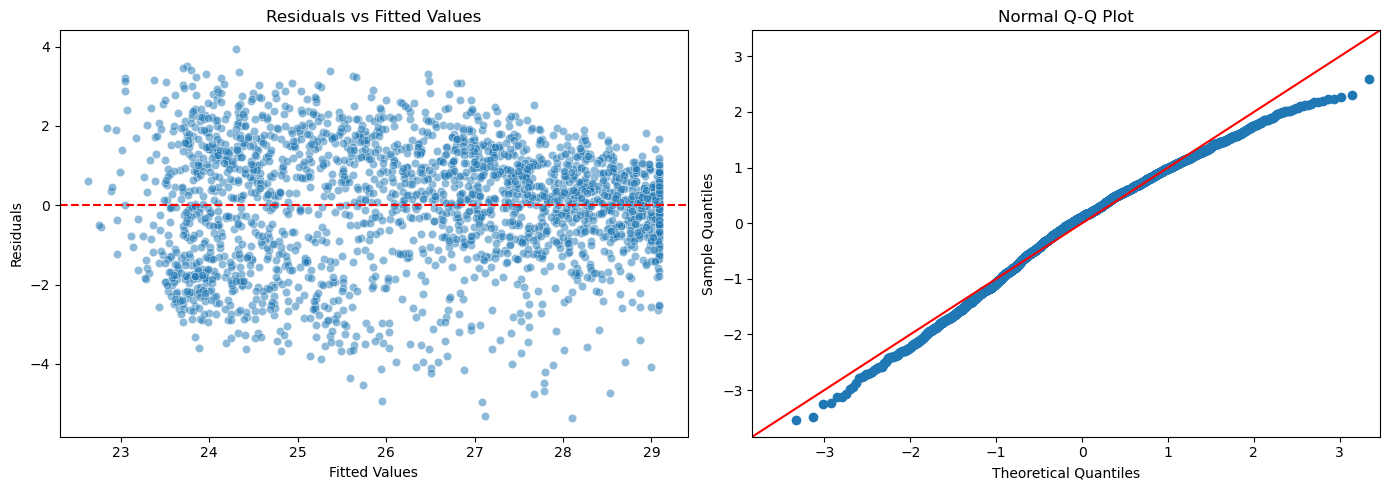

In [20]:
def validate_mlr(mlr_model, df, feature_cols):
  """Validates OLS regression assumptions: normality, homoscedasticity, and multicollinearity."""
  residuals = mlr_model.resid
  fitted_vals = mlr_model.fittedvalues

  # 1. Check Multicollinearity (VIF)
  # VIF > 5 or 10 indicates high multicollinearity
  X_vif = sm.add_constant(df[feature_cols].dropna())
  vif_data = pd.DataFrame()
  vif_data["Feature"] = X_vif.columns[
      1:
  ]  # Exclude constant for feature view
  vif_data["VIF"] = [
      variance_inflation_factor(X_vif.values, i)
      for i in range(1, X_vif.shape[1])
  ]

  print("--- Multicollinearity Check (VIF) ---")
  print(vif_data)
  print(
      "\n(Rule of thumb: VIF > 5 or 10 suggests problematic multicollinearity)\n"
  )

  # 2. Plots for Residuals (Normality & Homoscedasticity)
  fig, axes = plt.subplots(1, 2, figsize=(14, 5))

  # Residuals vs Fitted (Checks Homoscedasticity / Non-linearity)
  sns.scatterplot(x=fitted_vals, y=residuals, ax=axes[0], alpha=0.5)
  axes[0].axhline(0, color="red", linestyle="--")
  axes[0].set_title("Residuals vs Fitted Values")
  axes[0].set_xlabel("Fitted Values")
  axes[0].set_ylabel("Residuals")

  # Q-Q Plot (Checks Normality of Residuals)
  sm.qqplot(residuals, line="45", fit=True, ax=axes[1])
  axes[1].set_title("Normal Q-Q Plot")

  plt.tight_layout()
  plt.show()


# --- Run validation on your MLR model ---
validate_mlr(mlr_model, grid, features)

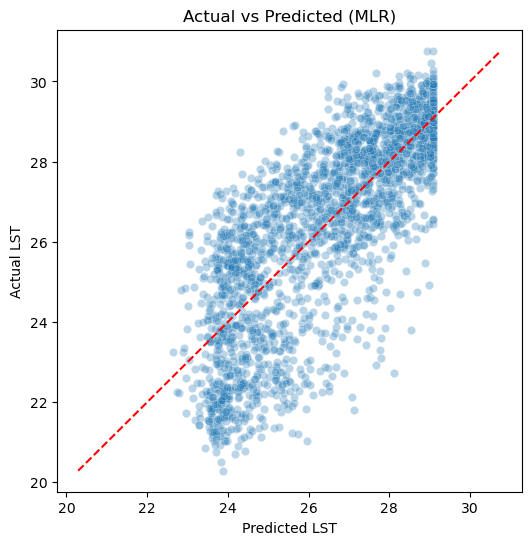

In [21]:
plt.figure(figsize=(6, 6))
sns.scatterplot(x=mlr_model.fittedvalues, y=grid[target].dropna(), alpha=0.3)
plt.plot([grid[target].min(), grid[target].max()],
         [grid[target].min(), grid[target].max()],
         color='red', linestyle='--')
plt.xlabel("Predicted LST")
plt.ylabel("Actual LST")
plt.title("Actual vs Predicted (MLR)")
plt.show()

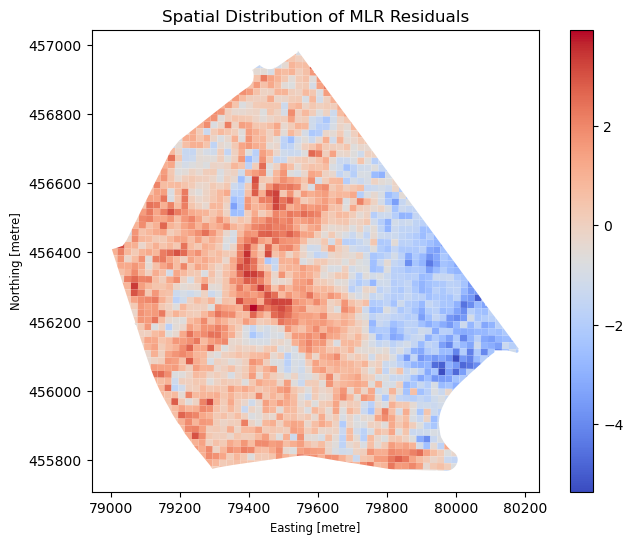

In [22]:
grid['mlr_residuals'] = grid[target] - mlr_model.fittedvalues

fig, ax = plt.subplots(1, 1, figsize=(8, 6))

# Use markersize=10 if your geometries are points, or omit it if they are polygons
grid.plot(
    column="mlr_residuals", cmap="coolwarm", legend=True, ax=ax, markersize=10
)

ax.set_title("Spatial Distribution of MLR Residuals")
plt.show()

Spearman Correlation Matrix:
                            LST_Mean_Morning  LST_Mean_Afternoon  \
LST_Mean_Morning                    1.000000            0.389886   
LST_Mean_Afternoon                  0.389886            1.000000   
LST_Mean_Evening                    0.142025            0.276552   
LST_Mean_Night                      0.121410            0.230401   
boomkroonvolume_m3                 -0.185721           -0.230227   
boomkroonoppervlakte_m2            -0.183152           -0.234062   
biomassa_bermudez_kg               -0.184893           -0.232329   
percentage_green_shadow            -0.172606           -0.195057   
percentage_grey_shadow              0.072866            0.094702   
percentage_combined_shadow         -0.141225           -0.123267   
percentage_onverhard               -0.164672           -0.267371   
percentage_verharding               0.203432            0.267522   

                            LST_Mean_Evening  LST_Mean_Night  \
LST_Mean_Morning      

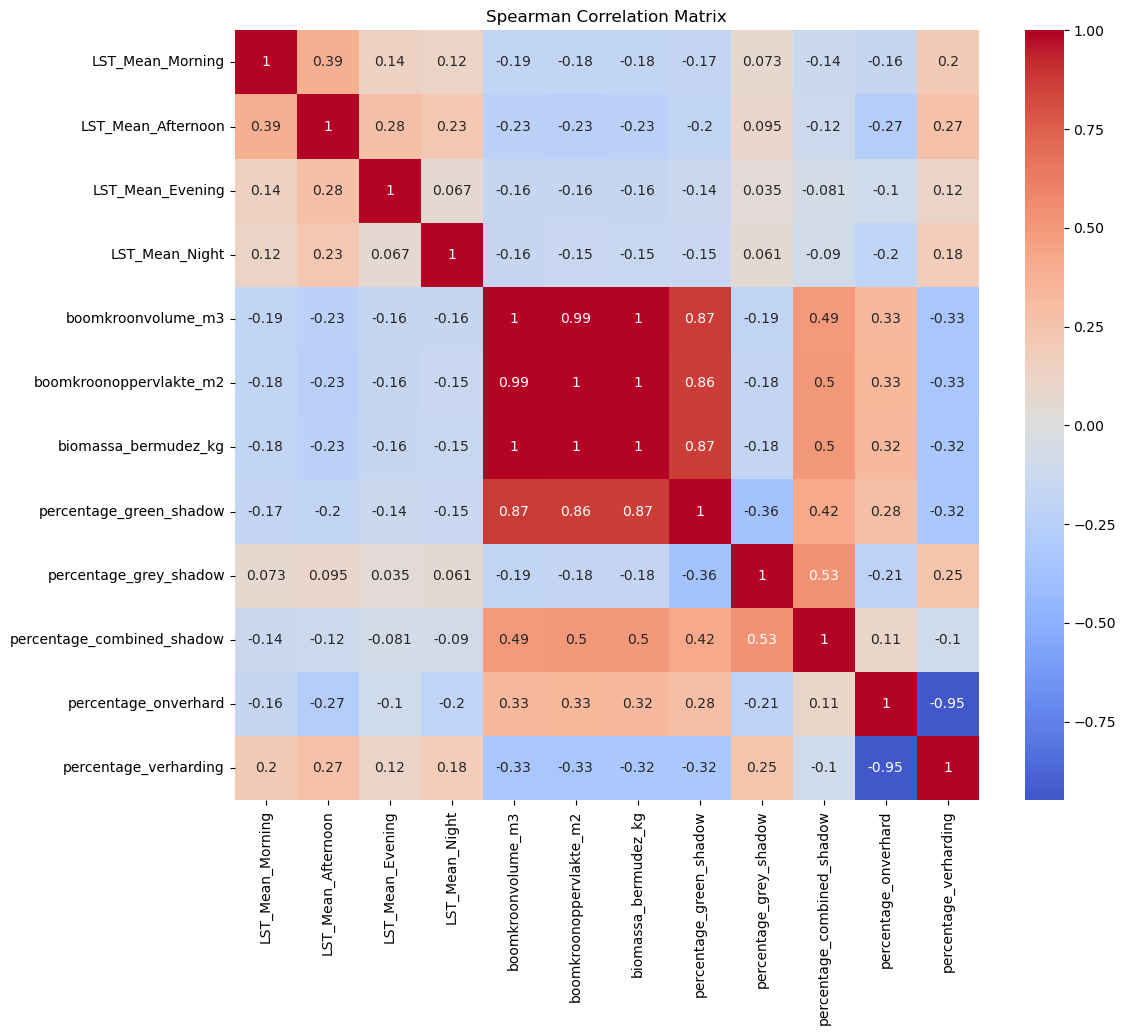

In [28]:
correlation_variables = ['LST_Mean_Morning', 'LST_Mean_Afternoon', 'LST_Mean_Evening', 'LST_Mean_Night',
                         'boomkroonvolume_m3', 'boomkroonoppervlakte_m2', 'biomassa_bermudez_kg',
                         'percentage_green_shadow', 'percentage_grey_shadow', 'percentage_combined_shadow',
                         'percentage_onverhard', 'percentage_verharding']

grid_statistics = grid[correlation_variables].copy()

spearman_corr = grid_statistics.corr(method='spearman')

print("Spearman Correlation Matrix:")
print(spearman_corr)

plt.figure(figsize=(12, 10))
sns.heatmap(spearman_corr, annot=True, cmap='coolwarm', center=0)
plt.title('Spearman Correlation Matrix')
plt.show()

In [29]:
# Ordinary Least Squares (OLS) Regression, Multiple Linear Regression
import statsmodels.api as sm

y = grid['LST_Mean_Afternoon']  # Dependent variable
X = grid[['biomassa_bermudez_kg', 'percentage_onverhard']]  # Independent variables

X = sm.add_constant(X)  # Adds a constant term to the predictor
model = sm.OLS(y, X).fit()  # Fit the model

print(model.summary())  # Print the summary of the regression results

# residuals = model.resid

# fig, ax = plt.subplots(figsize=(8, 5))
# ax.scatter(y_pred, residuals, alpha=0.3, color='purple')
# ax.axhline(0, color='red', linestyle='--', linewidth=1)
# ax.set_xlabel('Predicted Values')
# ax.set_ylabel('Residuals (Actual - Predicted)')
# ax.set_title('Residual Plot')
# plt.show()

                            OLS Regression Results                            
Dep. Variable:     LST_Mean_Afternoon   R-squared:                       0.096
Model:                            OLS   Adj. R-squared:                  0.096
Method:                 Least Squares   F-statistic:                     207.3
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           2.89e-86
Time:                        15:01:21   Log-Likelihood:                -5461.1
No. Observations:                3886   AIC:                         1.093e+04
Df Residuals:                    3883   BIC:                         1.095e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                   29.9757 

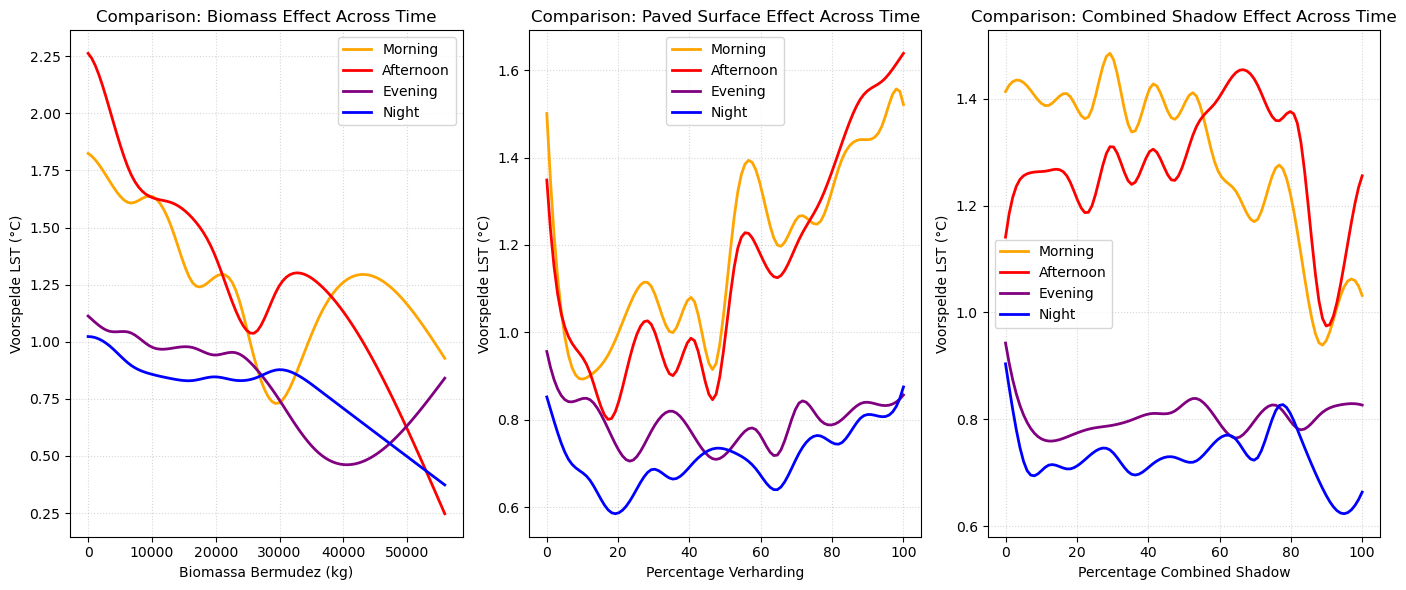

In [30]:
from pygam import LinearGAM, s

X = grid[['biomassa_bermudez_kg', 'percentage_verharding', 'percentage_combined_shadow']]
target_columns = { 
    'Morning': 'LST_Mean_Morning', 
    'Afternoon': 'LST_Mean_Afternoon', 
    'Evening': 'LST_Mean_Evening',
    'Night': 'LST_Mean_Night'
}

# Colors for each time block
colors = {'Night': 'blue', 'Morning': 'orange', 'Afternoon': 'red', 'Evening': 'purple'}

# Create a figure with 2 subplots side by side (one for each variable)
fig, axs = plt.subplots(1, 3, figsize=(14, 6))

# Loop through all time blocks, fit models, and plot lines on the same axes
for tod, col in target_columns.items():
    y = grid[col]
    gam = LinearGAM(s(0) + s(1) + s(2)).fit(X, y)
    
    # 1. Biomass plot (Term 0)
    XX_bio = gam.generate_X_grid(term=0)
    axs[0].plot(XX_bio[:, 0], gam.partial_dependence(term=0, X=XX_bio), label=tod, color=colors[tod], lw=2)
    
    # 2. Paved surface plot (Term 1)
    XX_paved = gam.generate_X_grid(term=1)
    axs[1].plot(XX_paved[:, 1], gam.partial_dependence(term=1, X=XX_paved), label=tod, color=colors[tod], lw=2)

    # 3. Combined shadow plot (Term 2)
    XX_combined_shadow = gam.generate_X_grid(term=2)
    axs[2].plot(XX_combined_shadow[:, 2], gam.partial_dependence(term=2, X=XX_combined_shadow), label=tod, color=colors[tod], lw=2)

# Format Biomass plot
axs[0].set_title('Comparison: Biomass Effect Across Time')
axs[0].set_xlabel('Biomassa Bermudez (kg)')
axs[0].set_ylabel('Voorspelde LST (°C)')
axs[0].grid(True, linestyle=':', alpha=0.5)
axs[0].legend()

# Format Paved plot
axs[1].set_title('Comparison: Paved Surface Effect Across Time')
axs[1].set_xlabel('Percentage Verharding')
axs[1].set_ylabel('Voorspelde LST (°C)')
axs[1].grid(True, linestyle=':', alpha=0.5)
axs[1].legend()

# Format Combined Shadow plot
axs[2].set_title('Comparison: Combined Shadow Effect Across Time')
axs[2].set_xlabel('Percentage Combined Shadow')
axs[2].set_ylabel('Voorspelde LST (°C)')
axs[2].grid(True, linestyle=':', alpha=0.5)
axs[2].legend()

plt.tight_layout()
plt.show()

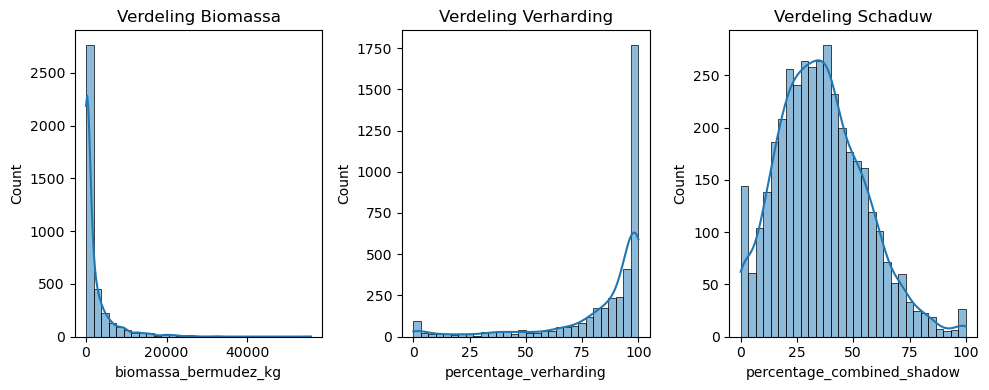

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

# Maak een histogram om te zien waar je datapunten geconcentreerd zijn
plt.figure(figsize=(10, 4))

plt.subplot(1, 3, 1)
sns.histplot(grid['biomassa_bermudez_kg'], bins=30, kde=True)
plt.title('Verdeling Biomassa')

plt.subplot(1, 3, 2)
sns.histplot(grid['percentage_verharding'], bins=30, kde=True)
plt.title('Verdeling Verharding')

plt.subplot(1, 3, 3)
sns.histplot(grid['percentage_combined_shadow'], bins=30, kde=True)
plt.title('Verdeling Schaduw')

plt.tight_layout()
plt.show()

In [ ]:
# import pandas as pd
# import glob
# import os
# from scipy.spatial import cKDTree

# # 1. Geef het pad op naar de map met je losse tile .xyz bestanden
# input_folder = "Input//"
# all_files = glob.glob(os.path.join(input_folder, "*.xyz"))

# print(f"Gevonden tiles: {len(all_files)}")

# df_list = []
# for filename in all_files:
#     df_tile = pd.read_csv(filename, header=None, names=['X', 'Y', 'Z'], sep=None, engine='python')
#     df_list.append(df_tile)

# df_combined = pd.concat(df_list, ignore_index=True)
# print(f"Totaal aantal punten vóór ontdubbeling: {len(df_combined)}")

# # Rond X en Y af op 2 decimalen (1 cm precisie) 
# # Punten die door de tegel-overlap exact op dezelfde plek staan worden zo gedetecteerd
# df_combined['X_rounded'] = df_combined['X'].round(2)
# df_combined['Y_rounded'] = df_combined['Y'].round(2)

# # Sorteer op hoogte (Z) zodat bij een dubbel punt het hoogste punt behouden blijft
# df_combined = df_combined.sort_values(by='Z', ascending=False)

# # Verwijder alleen de dubbelen op centimeter-niveau
# df_clean = df_combined.drop_duplicates(subset=['X_rounded', 'Y_rounded']).drop(columns=['X_rounded', 'Y_rounded']).reset_index(drop=True)

# print(f"Totaal aantal punten na centimeter-ontdubbeling: {len(df_clean)}")

# output_file = os.path.join(input_folder, "vegetatie_alles_schoon.xyz")
# df_clean.to_csv(output_file, index=False, header=False, sep=' ')

Gevonden tiles: 5
Totaal aantal punten vóór ontdubbeling: 19244526
Totaal aantal punten na centimeter-ontdubbeling: 17499682
